In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sathsaranii/oxford-17-category-flower-dataset/17flowers.tgz


# Dataset loading and Preprocessing


In [2]:
import os
import tarfile

dataset_path = "/kaggle/input/datasets/sathsaranii/oxford-17-category-flower-dataset/17flowers.tgz"
extract_path = "/kaggle/working/flower_dataset"

with tarfile.open(dataset_path, "r:gz") as tar:
    tar.extractall(path=extract_path, filter="data")

print("Dataset extracted successfully!")
print("Total images:", len(os.listdir(extract_path + "/jpg")))

Dataset extracted successfully!
Total images: 1362


In [3]:
import shutil

source_dir = "/kaggle/working/flower_dataset/jpg"
output_dir = "/kaggle/working/selected_dataset"

classes = {
    "Daffodil": (1, 80),
    "Iris": (401, 480),
    "Tulip": (561, 640),
    "Sunflower": (721, 800),
    "Daisy": (801, 880)
}

for flower, (start, end) in classes.items():
    class_dir = os.path.join(output_dir, flower)
    os.makedirs(class_dir, exist_ok=True)
    for i in range(start, end + 1):
        filename = f"image_{i:04d}.jpg"
        shutil.copy2(
            os.path.join(source_dir, filename),
            os.path.join(class_dir, filename)
        )
    print(f"{flower}: {len(os.listdir(class_dir))} images")

Daffodil: 80 images
Iris: 80 images
Tulip: 80 images
Sunflower: 80 images
Daisy: 80 images


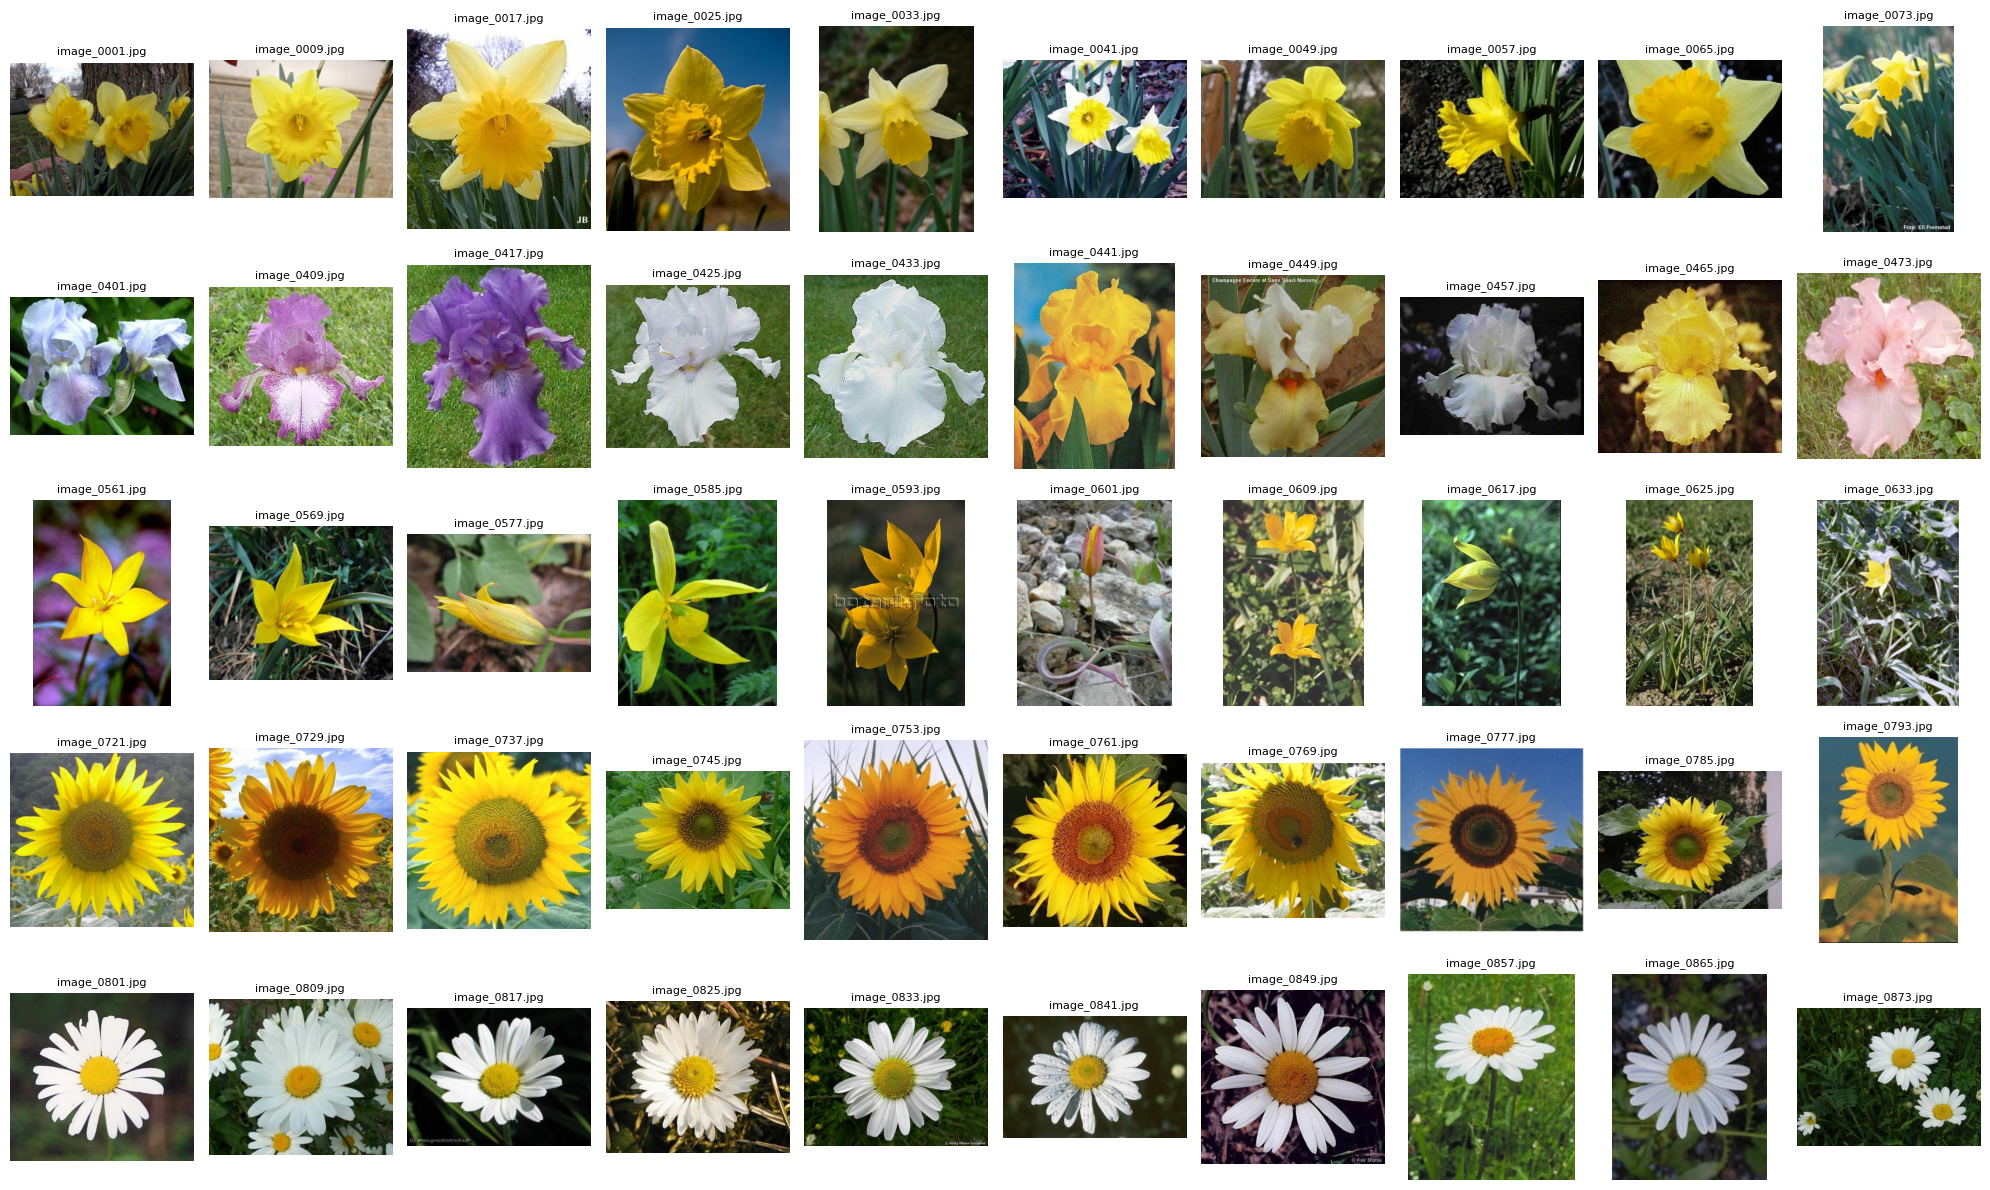

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(5, 10, figsize=(20, 12))

for row, flower in enumerate(classes.keys()):
    folder = os.path.join(output_dir, flower)
    
    # Select 10 images from each class
    filenames = sorted(os.listdir(folder))[::8][:10]
    for col, filename in enumerate(filenames):
        img = Image.open(os.path.join(folder, filename))
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        
        if col == 0:
            axes[row, col].set_ylabel(
                flower,
                fontsize=14,
                rotation=0,
                labelpad=50
            )
        axes[row, col].set_title(filename, fontsize=8)
plt.tight_layout()
plt.show()

### Train-Validation-Evaluation Split

In [5]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Dataset location
dataset_dir = "/kaggle/working/selected_dataset"

# Fixed random seed
SEED = 42

# Collect image paths and labels
data = []

for flower in sorted(os.listdir(dataset_dir)):
    class_dir = os.path.join(dataset_dir, flower)

    if not os.path.isdir(class_dir):
        continue

    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith(".jpg"):
            data.append({
                "filepath": os.path.join(class_dir, filename),
                "label": flower
            })

df = pd.DataFrame(data)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

# Save splits
split_dir = "/kaggle/working/splits"
os.makedirs(split_dir, exist_ok=True)

train_df.to_csv(f"{split_dir}/train.csv", index=False)
val_df.to_csv(f"{split_dir}/val.csv", index=False)
test_df.to_csv(f"{split_dir}/test.csv", index=False)

print("Dataset split completed!")
print(f"Training: {len(train_df)} images")
print(f"Validation: {len(val_df)} images")
print(f"Testing: {len(test_df)} images")

Dataset split completed!
Training: 280 images
Validation: 60 images
Testing: 60 images


In [6]:
# Verify class distribution
distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
})

distribution.loc["Total"] = distribution.sum()
display(distribution)

# Verify no overlapping images
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

assert len(train_paths | val_paths | test_paths) == 400

print("All dataset split checks passed!")

,Training,Validation,Testing
label,,,
Daffodil,56,12,12
Daisy,56,12,12
Iris,56,12,12
Sunflower,56,12,12
Tulip,56,12,12
Total,280,60,60


All dataset split checks passed!


### Resize images into 96 x 96 x 3 

In [7]:
from PIL import Image
import numpy as np

def load_and_resize_image(filepath):
    img = Image.open(filepath).convert("RGB")
    img = img.resize((96, 96), Image.Resampling.BILINEAR)
    img_array = np.array(img)

    return img_array

# Resize all images in each dataset
X_train = np.array([load_and_resize_image(path) for path in train_df["filepath"]])
X_val = np.array([load_and_resize_image(path) for path in val_df["filepath"]])
X_test = np.array([load_and_resize_image(path) for path in test_df["filepath"]])

# Verify dimensions
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (280, 96, 96, 3)
Validation: (60, 96, 96, 3)
Testing: (60, 96, 96, 3)


In [8]:
# Verify every image has the correct dimensions
assert X_train.shape == (280, 96, 96, 3)
assert X_val.shape == (60, 96, 96, 3)
assert X_test.shape == (60, 96, 96, 3)

print("All 400 images successfully resized to 96 × 96 × 3!")

All 400 images successfully resized to 96 × 96 × 3!


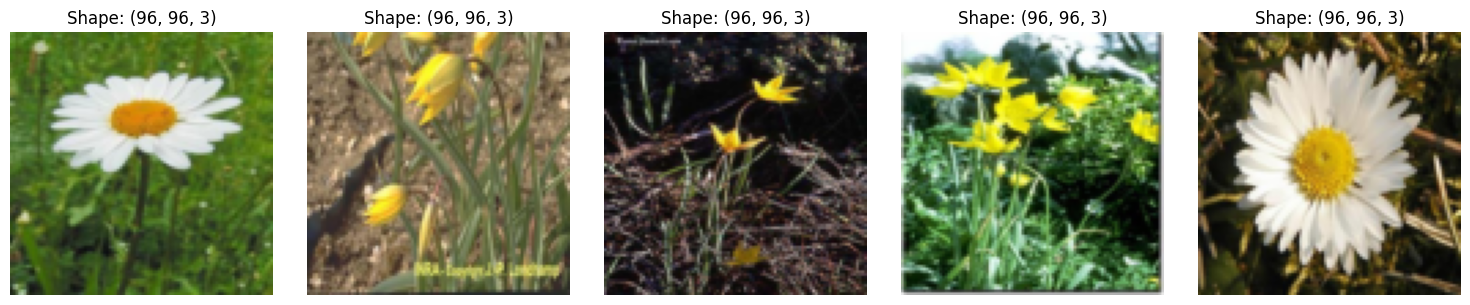

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i in range(5):
    axes[i].imshow(X_train[i])
    axes[i].set_title(f"Shape: {X_train[i].shape}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### Scale Pixel Values to [0, 1]

In [10]:
# Scale pixel values to [0, 1]
X_train = X_train.astype(np.float32) / 255.0
X_val = X_val.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Training:", X_train.min(), X_train.max())
print("Validation:", X_val.min(), X_val.max())
print("Testing:", X_test.min(), X_test.max())

# Verify all pixel values are within [0, 1]
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_val.min() <= X_val.max() <= 1
assert 0 <= X_test.min() <= X_test.max() <= 1

print("All images successfully scaled to [0, 1]!")

Training: 0.0 1.0
Validation: 0.0 1.0
Testing: 0.0 1.0
All images successfully scaled to [0, 1]!


###     Standardize using the mean and standard deviation 

In [11]:
# Calculate mean and standard deviation from TRAINING images only
mean = X_train.mean(axis=(0, 1, 2))
std = X_train.std(axis=(0, 1, 2))

print("Training Mean (RGB):", mean)
print("Training Std (RGB):", std)

Training Mean (RGB): [0.4302922 0.4274832 0.2729238]
Training Std (RGB): [0.28139123 0.25252956 0.25337297]


In [12]:
import numpy as np

# Standardize using training statistics
X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

# Verify training mean is approximately 0
print("Mean after standardization:")
print(X_train.mean(axis=(0, 1, 2)))

# Verify training standard deviation is approximately 1
print("\nStd after standardization:")
print(X_train.std(axis=(0, 1, 2)))

# Check for invalid values
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

print("\nStandardization completed successfully!")

Mean after standardization:
[-0.00103551 -0.00126504 -0.00235678]

Std after standardization:
[1.0000359  0.99946105 1.0001917 ]

Standardization completed successfully!


### One-hot encoding lables

In [13]:
# Define label mapping
class_to_idx = {
    "Daffodil": 0,
    "Daisy": 1,
    "Iris": 2,
    "Sunflower": 3,
    "Tulip": 4
}

# Convert labels to integers
y_train = train_df["label"].map(class_to_idx).to_numpy()
y_val = val_df["label"].map(class_to_idx).to_numpy()
y_test = test_df["label"].map(class_to_idx).to_numpy()

print("Training labels:", y_train[:10])
print("Validation labels:", y_val[:10])
print("Testing labels:", y_test[:10])

Training labels: [1 4 4 4 1 1 4 2 4 4]
Validation labels: [1 4 4 3 3 2 1 4 0 0]
Testing labels: [1 3 1 4 1 3 1 2 3 3]


In [14]:
import numpy as np

# Check number of labels
assert len(y_train) == 280
assert len(y_val) == 60
assert len(y_test) == 60

# Check label values
assert set(np.unique(y_train)) == {0, 1, 2, 3, 4}
assert set(np.unique(y_val)) == {0, 1, 2, 3, 4}
assert set(np.unique(y_test)) == {0, 1, 2, 3, 4}

print("Label encoding completed successfully!")

print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)
print("Testing labels shape:", y_test.shape)

Label encoding completed successfully!
Training labels shape: (280,)
Validation labels shape: (60,)
Testing labels shape: (60,)


# Baseline Classifier

Input Image (96 × 96 × 3)
         │
         ▼
Conv2D (32 filters, 3×3, ReLU, Same Padding)
         │
         ▼
MaxPooling2D (2×2)
         │
         ▼
Conv2D (64 filters, 3×3, ReLU, Same Padding)
         │
         ▼
MaxPooling2D (2×2)
         │
         ▼
Conv2D (128 filters, 3×3, ReLU, Same Padding)
         │
         ▼
MaxPooling2D (2×2)
         │
         ▼
GlobalAveragePooling2D
         │
         ▼
Dense (64 neurons, ReLU)
         │
         ▼
Dropout (0.3)
         │
         ▼
Dense (5 neurons, Softmax)
         │
         ▼
Predicted Flower Class

In [15]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Set random seeds for reproducibility
SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [16]:
def build_cnn():
    model = models.Sequential([
        layers.Input(shape=(96, 96, 3)),

        # First convolutional block
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Second convolutional block
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Third convolutional block
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Classification layers
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),

        # Output: 5 flower classes
        layers.Dense(5, activation="softmax")
    ])

    return model


model = build_cnn()

# Print architecture summary
model.summary()

2026-10-09 06:54:38.781998: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,829 (397.77 KB)

 Trainable params: 101,829 (397.77 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train the baseline CNN

In [18]:
import os

os.makedirs("/kaggle/working/models", exist_ok=True)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath="/kaggle/working/models/baseline_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=50,
    batch_size=16,

    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step - accuracy: 0.3179 - loss: 1.5316 - val_accuracy: 0.3833 - val_loss: 1.5511
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - accuracy: 0.4286 - loss: 1.3411 - val_accuracy: 0.5167 - val_loss: 1.3055
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step - accuracy: 0.5107 - loss: 1.1502 - val_accuracy: 0.5333 - val_loss: 1.2202
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - accuracy: 0.5643 - loss: 1.0691 - val_accuracy: 0.5500 - val_loss: 1.1333
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.5571 - loss: 1.0167 - val_accuracy: 0.5333 - val_loss: 1.0771
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - accuracy: 0.6393 - loss: 0.9442 - val_accuracy: 0.6000 - val_loss: 1.0301
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.6393 - loss: 0.9096 - val_accuracy: 0.6333 - val_loss: 0.9293
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.6250 - loss: 0.8836 - val_accuracy: 0.

### Accuracy and Loss Graphs

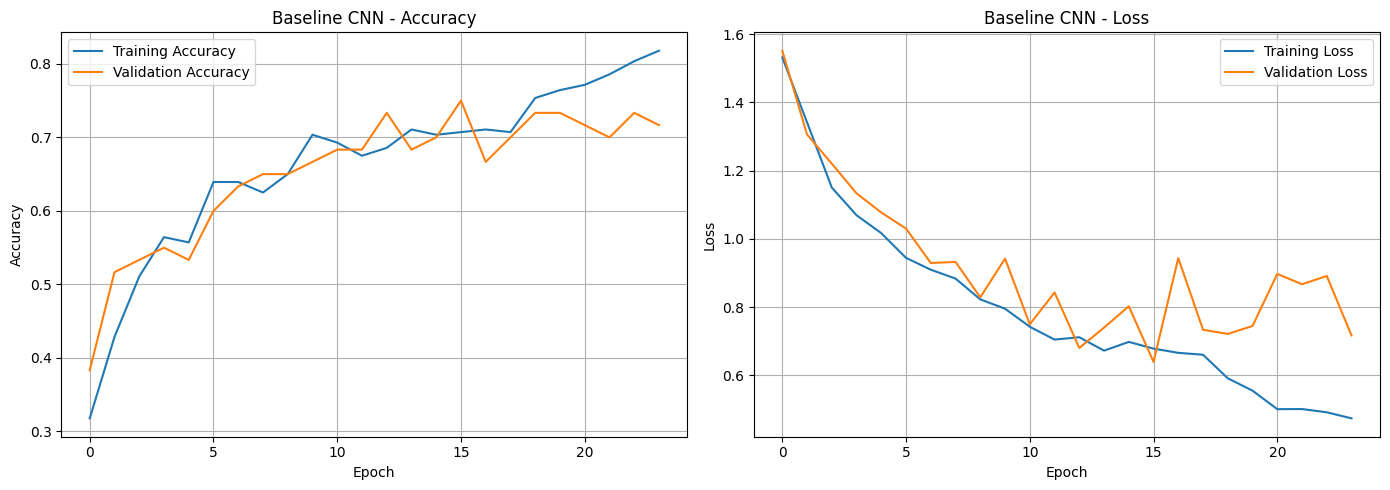

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")

axes[0].set_title("Baseline CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")

axes[1].set_title("Baseline CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Evaluate the Baseline CNN

In [20]:
# Load the saved baseline model
best_model = tf.keras.models.load_model(
    "/kaggle/working/models/baseline_best.keras"
)

# Evaluate baseline model on test set
baseline_test_loss, baseline_test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Best epoch selected using validation loss
baseline_best_epoch = np.argmin(
    history.history["val_loss"]
) + 1

print("BASELINE CNN RESULTS")
print("-------------------------")
print(f"Best Epoch: {baseline_best_epoch}")
print(f"Test Accuracy: {baseline_test_accuracy * 100:.2f}%")
print(f"Test Loss: {baseline_test_loss:.4f}")

BASELINE CNN RESULTS
-------------------------
Best Epoch: 16
Test Accuracy: 65.00%
Test Loss: 0.7553


### Additional Evaluation Metrics

In [21]:
from sklearn.metrics import classification_report, confusion_matrix

predictions = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

class_names = [
    "Daffodil",
    "Daisy",
    "Iris",
    "Sunflower",
    "Tulip"
]

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

    Daffodil       0.20      0.08      0.12        12
       Daisy       0.92      0.92      0.92        12
        Iris       0.91      0.83      0.87        12
   Sunflower       0.62      0.67      0.64        12
       Tulip       0.47      0.75      0.58        12

    accuracy                           0.65        60
   macro avg       0.62      0.65      0.62        60
weighted avg       0.62      0.65      0.62        60


Confusion Matrix:
[[ 1  0  0  4  7]
 [ 0 11  1  0  0]
 [ 1  0 10  1  0]
 [ 1  0  0  8  3]
 [ 2  1  0  0  9]]


# Image Augmentation

In [22]:
from PIL import Image
import numpy as np

def load_original_image(filepath):
    image = Image.open(filepath).convert("RGB")
    image = image.resize((96, 96), Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32) / 255.0

X_train_original = np.array([
    load_original_image(path)
    for path in train_df["filepath"]
])

print("Shape:", X_train_original.shape)
print("Min:", X_train_original.min())
print("Max:", X_train_original.max())

Shape: (280, 96, 96, 3)
Min: 0.0
Max: 1.0


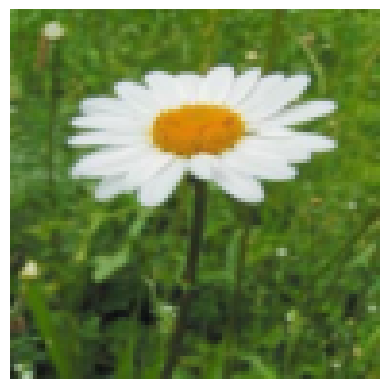

In [23]:
plt.imshow(X_train_original[0])

plt.axis("off")

plt.show()

In [24]:
import tensorflow as tf
from tensorflow.keras import layers

SEED = 42
tf.keras.utils.set_random_seed(SEED)

augmentation_pipeline = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.0556, fill_mode="reflect"),
    layers.RandomZoom(
        height_factor=0.15,
        width_factor=0.15,
        fill_mode="reflect"
    ),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    )
], name="flower_augmentation")

###  Generate Augmented Images

In [25]:
import numpy as np

AUGMENTATIONS_PER_IMAGE = 3

augmented_images = []
augmented_labels = []

for image, label in zip(X_train_original, y_train):

    for _ in range(AUGMENTATIONS_PER_IMAGE):

        # Apply geometric transformations
        augmented = augmentation_pipeline(
            image[np.newaxis, ...],
            training=True
        )[0].numpy()

        # Apply random brightness adjustment
        brightness_factor = np.random.uniform(0.85, 1.15)

        augmented = np.clip(
            augmented * brightness_factor,
            0.0,
            1.0
        )

        augmented_images.append(augmented)
        augmented_labels.append(label)

X_augmented_raw = np.array(
    augmented_images,
    dtype=np.float32
)

y_augmented = np.array(
    augmented_labels,
    dtype=np.int64
)

print("Augmented images:", X_augmented_raw.shape)
print("Augmented labels:", y_augmented.shape)

Augmented images: (840, 96, 96, 3)
Augmented labels: (840,)


### Combine Original and Augmented Images

In [26]:
X_augmented = (
    X_augmented_raw - mean
) / std

X_train_augmented = np.concatenate(
    [X_train, X_augmented],
    axis=0
)

y_train_augmented = np.concatenate(
    [y_train, y_augmented],
    axis=0
)

print("Final training images:", X_train_augmented.shape)
print("Final training labels:", y_train_augmented.shape)

Final training images: (1120, 96, 96, 3)
Final training labels: (1120,)


In [27]:
import pandas as pd

class_names = [
    "Daffodil",
    "Daisy",
    "Iris",
    "Sunflower",
    "Tulip"
]

statistics = []

for class_id, class_name in enumerate(class_names):

    original_count = np.sum(y_train == class_id)

    augmented_count = np.sum(y_augmented == class_id)

    total_count = np.sum(y_train_augmented == class_id)

    statistics.append({
        "Class": class_name,
        "Original": original_count,
        "Generated": augmented_count,
        "Final Total": total_count
    })

stats_df = pd.DataFrame(statistics)

display(stats_df)

print("Total original:", len(y_train))
print("Total generated:", len(y_augmented))
print("Final training size:", len(y_train_augmented))

,Class,Original,Generated,Final Total
0,Daffodil,56,168,224
1,Daisy,56,168,224
2,Iris,56,168,224
3,Sunflower,56,168,224
4,Tulip,56,168,224


Total original: 280
Total generated: 840
Final training size: 1120


### Visualize Original vs Augmented Images

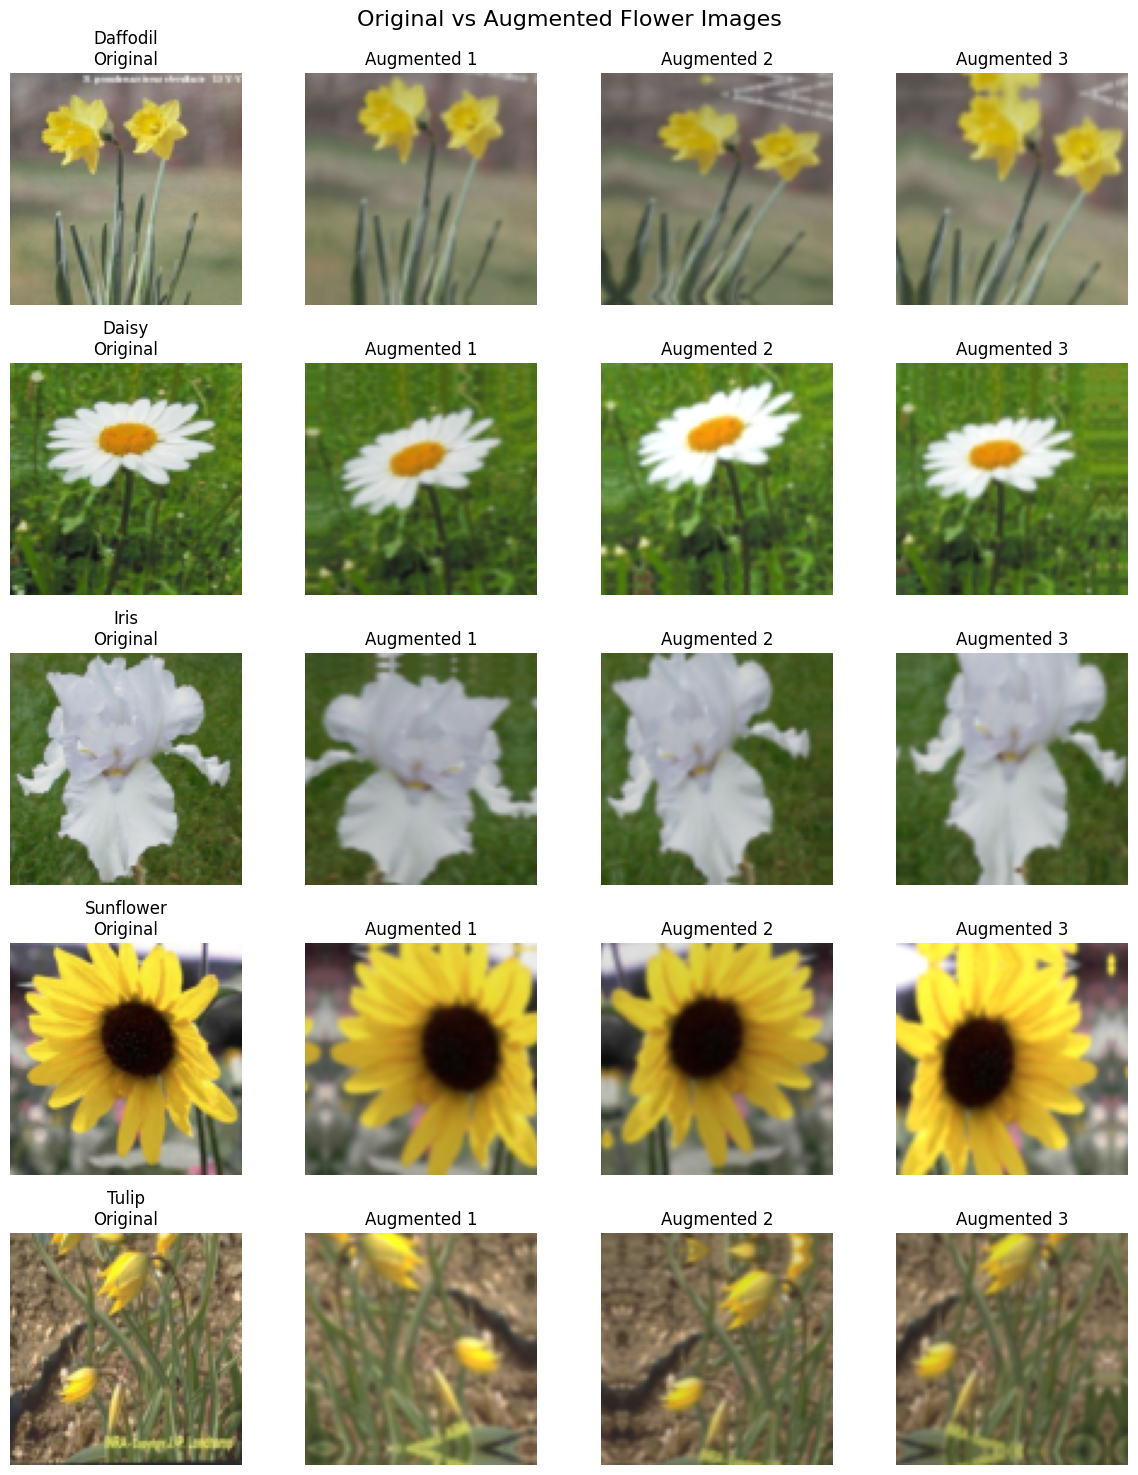

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    5, 4,
    figsize=(12, 15)
)

for class_id, class_name in enumerate(class_names):

    # Find the first training image belonging to this class
    original_idx = np.where(y_train == class_id)[0][0]

    original_image = X_train_original[original_idx]

    # Display original
    axes[class_id, 0].imshow(original_image)
    axes[class_id, 0].set_title(f"{class_name}\nOriginal")
    axes[class_id, 0].axis("off")

    # Display its three generated variants
    start_idx = original_idx * AUGMENTATIONS_PER_IMAGE

    for j in range(AUGMENTATIONS_PER_IMAGE):

        augmented_image = X_augmented_raw[start_idx + j]

        axes[class_id, j + 1].imshow(augmented_image)
        axes[class_id, j + 1].set_title(f"Augmented {j + 1}")
        axes[class_id, j + 1].axis("off")

plt.suptitle(
    "Original vs Augmented Flower Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [29]:
import os
from PIL import Image

output_dir = "/kaggle/working/augmented_dataset"

os.makedirs(output_dir, exist_ok=True)

for class_id, class_name in enumerate(class_names):
    os.makedirs(
        os.path.join(output_dir, class_name),
        exist_ok=True
    )

for i, (image, label) in enumerate(
    zip(X_train_original, y_train)
):

    class_name = class_names[label]
    class_dir = os.path.join(output_dir, class_name)

    # Save original training image
    original_uint8 = (
        np.clip(image, 0, 1) * 255
    ).astype(np.uint8)

    Image.fromarray(original_uint8).save(
        os.path.join(class_dir, f"original_{i:04d}.png")
    )

    # Save three augmented variants
    for j in range(AUGMENTATIONS_PER_IMAGE):

        augmented_idx = i * AUGMENTATIONS_PER_IMAGE + j

        augmented_image = X_augmented_raw[augmented_idx]

        augmented_uint8 = (
            np.clip(augmented_image, 0, 1) * 255
        ).astype(np.uint8)

        Image.fromarray(augmented_uint8).save(
            os.path.join(
                class_dir,
                f"augmented_{i:04d}_{j+1}.png"
            )
        )

print("Augmented dataset saved successfully!")

Augmented dataset saved successfully!


In [30]:
for class_name in class_names:

    class_dir = os.path.join(output_dir, class_name)

    print(
        class_name,
        len(os.listdir(class_dir))
    )

Daffodil 224
Daisy 224
Iris 224
Sunflower 224
Tulip 224


In [31]:
import shutil

shutil.make_archive(
    "/kaggle/working/augmented_dataset",
    "zip",
    output_dir
)

print("ZIP file created.")

ZIP file created.


# Re-train model with augmented training set

### Verify the Augmented Training Data

In [32]:
print("Original training:", X_train.shape)
print("Augmented training:", X_train_augmented.shape)
print("Augmented labels:", y_train_augmented.shape)

print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Original training: (280, 96, 96, 3)
Augmented training: (1120, 96, 96, 3)
Augmented labels: (1120,)
Validation: (60, 96, 96, 3)
Test: (60, 96, 96, 3)


In [33]:
assert np.isfinite(X_train_augmented).all()
assert len(X_train_augmented) == len(y_train_augmented)

print("Dataset verification successful!")

Dataset verification successful!


### Create a New CNN and Configure Early Stopping

In [34]:
# Reset random seed
tf.keras.utils.set_random_seed(42)

# Create a new CNN
augmented_model = build_cnn()

# Compile using the same parameters as baseline
augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmented_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,829 (397.77 KB)

 Trainable params: 101,829 (397.77 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os

os.makedirs("/kaggle/working/models", exist_ok=True)

augmented_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath="/kaggle/working/models/augmented_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

### Train the CNN Using Augmented Data

In [36]:
history_augmented = augmented_model.fit(
    X_train_augmented,
    y_train_augmented,

    validation_data=(X_val, y_val),

    epochs=50,
    batch_size=16,

    callbacks=augmented_callbacks,
    verbose=1
)

Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.4661 - loss: 1.2501 - val_accuracy: 0.5333 - val_loss: 1.0986
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.5920 - loss: 0.9772 - val_accuracy: 0.5833 - val_loss: 0.9566
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 138ms/step - accuracy: 0.6455 - loss: 0.8786 - val_accuracy: 0.7000 - val_loss: 0.8366
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 132ms/step - accuracy: 0.7045 - loss: 0.7315 - val_accuracy: 0.7333 - val_loss: 0.7089
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 131ms/step - accuracy: 0.7411 - loss: 0.6502 - val_accuracy: 0.7167 - val_loss: 0.6868
Epoch 6/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.7518 - loss: 0.6009 - val_accuracy: 0.7500 - val_loss: 0.5924
Epoch 7/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 133ms/step - accuracy: 0.7804 - loss: 0.5682 - val_accuracy: 0.6833 - val_loss: 0.6217
Epoch 8/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 133ms/step - accuracy: 0.8196 - loss: 0.4784 - val_accuracy:

### Training Accuracy and Loss Plots

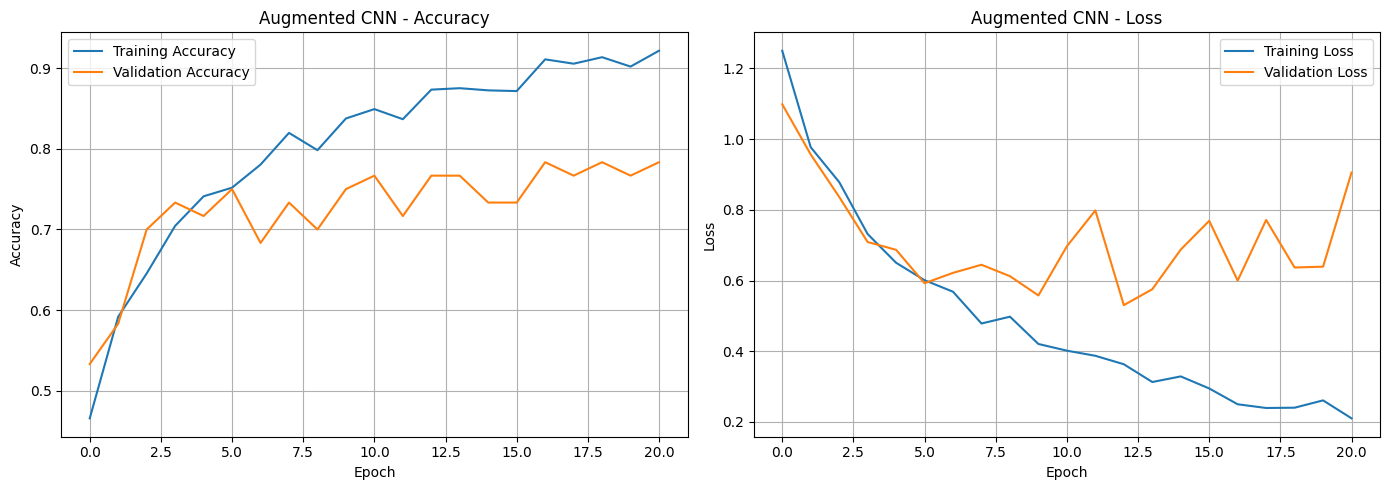

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    history_augmented.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history_augmented.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Augmented CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    history_augmented.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_augmented.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Augmented CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Evaluate the Augmented CNN

In [38]:
best_augmented_model = tf.keras.models.load_model(
    "/kaggle/working/models/augmented_best.keras"
)

aug_test_loss, aug_test_accuracy = best_augmented_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

best_aug_epoch = np.argmin(
    history_augmented.history["val_loss"]
) + 1

print(f"Best Epoch: {best_aug_epoch}")
print(f"Test Accuracy: {aug_test_accuracy * 100:.2f}%")
print(f"Test Loss: {aug_test_loss:.4f}")

Best Epoch: 13
Test Accuracy: 70.00%
Test Loss: 0.6890


### Compare Baseline and Augmented CNN

In [39]:
import pandas as pd
import numpy as np

# Load both saved models
best_model = tf.keras.models.load_model(
    "/kaggle/working/models/baseline_best.keras"
)

best_augmented_model = tf.keras.models.load_model(
    "/kaggle/working/models/augmented_best.keras"
)

# Evaluate both models on the SAME test dataset
baseline_loss, baseline_accuracy = best_model.evaluate(
    X_test, y_test, verbose=0
)

augmented_loss, augmented_accuracy = best_augmented_model.evaluate(
    X_test, y_test, verbose=0
)

# Get best epochs
baseline_epoch = np.argmin(history.history["val_loss"]) + 1

augmented_epoch = np.argmin(
    history_augmented.history["val_loss"]
) + 1

# Create comparison table
comparison = pd.DataFrame({
    "Metric": [
        "Training Images",
        "Best Epoch",
        "Test Accuracy (%)",
        "Test Loss"
    ],
    "Baseline CNN": [
        len(X_train),
        baseline_epoch,
        round(baseline_accuracy * 100, 2),
        round(baseline_loss, 4)
    ],
    "Augmented CNN": [
        len(X_train_augmented),
        augmented_epoch,
        round(augmented_accuracy * 100, 2),
        round(augmented_loss, 4)
    ]
})

display(comparison)

,Metric,Baseline CNN,Augmented CNN
0,Training Images,280.0000,1120.000
1,Best Epoch,16.0000,13.000
2,Test Accuracy (%),65.0000,70.000
3,Test Loss,0.7553,0.689


### Generate the Classification Report

In [40]:
from sklearn.metrics import classification_report, confusion_matrix

predictions = best_augmented_model.predict(
    X_test,
    verbose=0
)

y_pred_aug = np.argmax(predictions, axis=1)

print(
    classification_report(
        y_test,
        y_pred_aug,
        target_names=class_names,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_aug))

              precision    recall  f1-score   support

    Daffodil       0.45      0.42      0.43        12
       Daisy       0.92      0.92      0.92        12
        Iris       0.83      0.83      0.83        12
   Sunflower       1.00      0.67      0.80        12
       Tulip       0.47      0.67      0.55        12

    accuracy                           0.70        60
   macro avg       0.74      0.70      0.71        60
weighted avg       0.74      0.70      0.71        60

Confusion Matrix:
[[ 5  0  1  0  6]
 [ 0 11  1  0  0]
 [ 1  1 10  0  0]
 [ 1  0  0  8  3]
 [ 4  0  0  0  8]]


# Ablation Experiments